## 이상거래 탐지하기


### 이상거래 탐지란 무엇인가

이상거래 탐지 시스템(FDS)은 거래 정보에서 의심스러운 거래를 찾아 검토 대상으로 분류한다.
사기는 전체 거래에서 차지하는 비율이 작고, 정상 거래와 비슷한 특성을 보일 수 있다.

정상으로 확인된 거래로 모델을 학습하면 정상 패턴에서 벗어난 거래를 찾는 데 사용할 수 있다.  
Isolation Forest는 거래가 다른 거래들과 얼마나 쉽게 분리되는지로 이상 점수를 계산한다.  
오토인코더는 입력을 압축한 뒤 복원하고, 원래 입력과 복원값 사이의 오차로 이상 점수를 계산한다.

In [8]:
from urllib.request import urlretrieve
from pathlib import Path
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42


### 카드 거래 데이터 불러오기

ULB Credit Card Fraud Detection은 2013년 유럽 카드 사용자의 이틀간 거래를 담은 공개 데이터다.
원본은 284,807행이며 사기 거래는 492행으로 약 0.17%다. 한 행은 거래 한 건에 해당한다.
익명화된 거래 특성과 금액으로 거래의 이상 점수를 계산하고, 실제 사기 여부와 비교한다.


In [9]:
data_path = Path("data/creditcard.csv")
if not data_path.exists():
    # parents=True: 상위 폴더도 생성, exist_ok=True: 기존 폴더를 허용한다.
    data_path.parent.mkdir(parents=True, exist_ok=True)
    url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
    # urlretrieve: URL의 파일을 지정한 로컬 경로에 저장한다.
    urlretrieve(url, data_path)

raw_transactions = pd.read_csv(data_path)
# arange: 0부터 행 수 - 1까지 생성. insert: 원본 행 번호를 첫 열에 추가한다.
raw_transactions.insert(0, "record_id", np.arange(len(raw_transactions)))

display(raw_transactions.head())


,record_id,Time,V1,V2,V3,V4,V5,V6,V7,V8,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### 데이터의 변수

| 열 | 의미와 사용 |
| --- | --- |
| `V1`~`V28` | PCA로 변환된 익명 수치 특성, 모델 입력 |
| `Amount` | 거래 금액, 수치형 입력 |
| `Time` | 첫 거래부터의 경과 초, 거래 확인에 사용 |
| `Class` | 정상 0·사기 1, 정상 학습 거래 구성과 모델 선택·평가에 사용 |
| `record_id` | 거래를 찾기 위해 추가한 원본 행 번호 |

PCA는 여러 특성을 조합해 데이터의 변동을 표현하는 새로운 수치 축을 만드는 방법이다.
원래 특성의 의미가 공개되지 않아 `V1`~`V28`을 구체적인 소비 행동으로 해석하기는 어렵다.


### 탐색적 데이터 분석(EDA)

탐색적 데이터 분석(Exploratory Data Analysis, EDA)은 요약 통계와 그래프로 데이터의 분포와 변수 사이의 관계, 품질을 살펴보는 과정이다.
pandas의 요약 통계와 Matplotlib의 그래프로 결측값·중복, 범주별 비율, 값의 분포 등을 살펴본다.
탐색 결과를 바탕으로 필요한 전처리 방법을 판단한다.


### 결측값과 중복 확인

결측값은 값이 비어 있는 항목이다. 중복은 `record_id`를 제외한 원본 열의 값이 모두 같은 행으로 정의한다.

아래 출력에서 결측값과 중복 행의 수를 확인한다.


In [10]:
# 행마다 다른 record_id를 제외한 원본 열로 중복을 비교한다.
original_columns = raw_transactions.columns.drop("record_id").tolist()
# isna: 결측 여부를 표시. 두 번의 sum으로 모든 열의 결측값 수를 합친다.
print("결측값 수:", int(raw_transactions[original_columns].isna().sum().sum()))

# duplicated: 첫 행 이후 같은 값이 반복된 행을 True로 표시한다.
duplicate_mask = raw_transactions.duplicated(subset=original_columns)
print("중복 행 수:", int(duplicate_mask.sum()))


결측값 수: 0
중복 행 수: 1081


### 중복 제거

결측값은 없고, 첫 행을 제외한 중복 행은 1,081개다.
익명화된 자료만으로 같은 실제 거래가 반복 기록되었는지 확정하기는 어렵다.
여기서는 동일한 관측값이 학습·평가 집합에 함께 들어가는 것을 막기 위해 첫 행만 남긴다.


In [11]:
# subset: 중복을 비교할 열, keep="first": 첫 번째 행을 남긴다.
transactions = raw_transactions.drop_duplicates(
    subset=original_columns,
    keep="first",
).copy()

print("제거한 중복 행:", len(raw_transactions) - len(transactions))
print("사용할 거래 수:", len(transactions))
display(transactions["Class"].value_counts().rename("transactions"))

# Class가 0·1이므로 평균은 사기 거래의 비율이다.
fraud_rate = transactions["Class"].mean()
print(f"사기 비율: {fraud_rate:.3%}")

제거한 중복 행: 1081
사용할 거래 수: 283726


Class
0    283253
1       473
Name: transactions, dtype: int64

사기 비율: 0.167%


### 학습·검증·테스트 분리

사기 비율을 유지하며 학습 64%·검증 16%·테스트 20%로 무작위 분할한다.


In [12]:
# train_test_split: 입력과 같은 열을 가진 두 DataFrame을 반환한다.
train, test = train_test_split(
    transactions,
    test_size=0.2,  # 두 번째 집합의 비율
    stratify=transactions["Class"],  # 클래스 비율을 유지한다.
    random_state=SEED,  # 같은 무작위 분할을 재현한다.
)
train, validation = train_test_split(
    train,
    test_size=0.2,
    stratify=train["Class"],
    random_state=SEED,
)

parts = {"train": train, "validation": validation, "test": test}
display(pd.DataFrame([
    {
        "split": name,
        "transactions": len(frame),
        "fraud": int(frame["Class"].sum()),
        "fraud_rate": frame["Class"].mean(),
    }
    for name, frame in parts.items()
]))


,split,transactions,fraud,fraud_rate
0,train,181584,302,0.001663
1,validation,45396,76,0.001674
2,test,56746,95,0.001674


### 원본 거래 금액 살펴보기

학습 집합의 변환 전 `Amount`에서 중앙값·90% 분위수·99% 분위수·최댓값을 비교한다.
90% 분위수는 거래의 약 90%가 그 이하에 놓이는 금액이다.
금액이 주로 어느 범위에 모여 있는지, 큰 금액이 얼마나 멀리 떨어져 있는지 확인한다.


In [13]:
train_amount = train["Amount"]

# describe: 건수·평균·표준편차·최솟값·지정한 분위수·최댓값을 반환한다.
amount_summary = train_amount.describe(percentiles=[0.5, 0.9, 0.99])
display(amount_summary.to_frame(name="Amount"))
print("금액이 0인 학습 거래 수:", int((train_amount == 0).sum()))


,Amount
count,181584.000000
mean,88.425320
std,246.128471
min,0.000000
50%,22.210000
90%,204.000000
99%,1013.277900
max,19656.530000


금액이 0인 학습 거래 수: 1155


### 금액 분포와 로그 변환

중앙값과 99% 분위수에 비해 최댓값이 훨씬 크다. 소액 거래가 많고 일부 큰 금액이 오른쪽으로 길게 이어지는 분포다.
로그 변환은 큰 금액 사이의 간격을 압축해, 거래가 모여 있는 작은 금액 구간을 상대적으로 넓게 표현한다.

`log1p(x)`는 `log(1 + x)`를 계산한다. 금액이 0이면 결과도 0이므로 0원 거래에도 적용할 수 있다.

두 그래프는 같은 학습 거래의 변환 전후 분포다. 가로축은 각각 원래 금액과 로그 변환값이고, 세로축은 각 구간의 거래 수다.
로그 변환 후 값이 퍼지는 모양을 비교한다. 탐지 성능에 미치는 효과는 검증 결과로 판단한다.


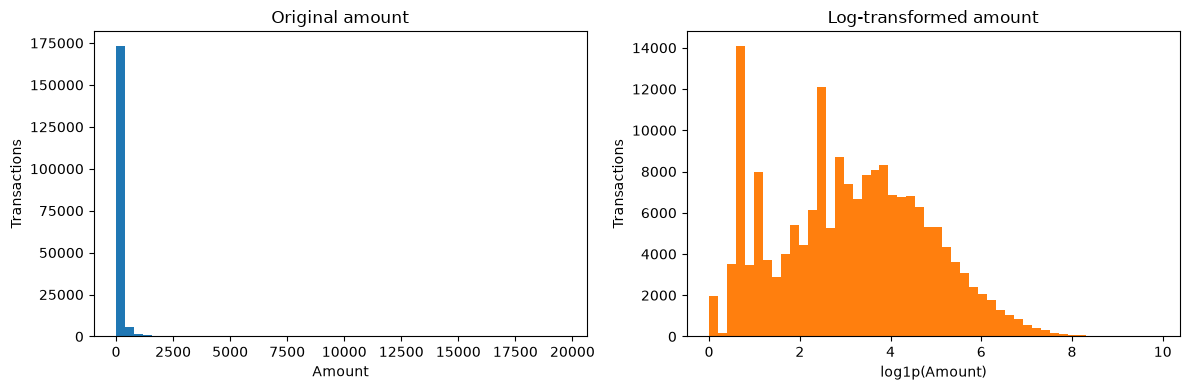

In [14]:
# 원래 금액과 같은 행 순서로 log(1 + 금액)을 계산한다.
log_train_amount = np.log1p(train_amount)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train_amount, bins=50, color="tab:blue")
axes[0].set(
    title="Original amount",
    xlabel="Amount",
    ylabel="Transactions",
)
axes[1].hist(log_train_amount, bins=50, color="tab:orange")
axes[1].set(
    title="Log-transformed amount",
    xlabel="log1p(Amount)",
    ylabel="Transactions",
)
plt.tight_layout()
plt.show()


### 모델 입력 만들기

`V1`~`V28`과 `log1p(Amount)`를 두 모델의 공통 입력으로 사용한다.
`Time`은 수집 시작 시점에 대한 상대값이므로 입력에서 제외하고, 거래를 확인할 때 사용한다.
`Class`와 `record_id`도 입력에서 제외한다.

Isolation Forest에는 로그 금액과 익명 특성을 그대로 전달한다.
오토인코더에는 특성별 크기 차이가 복원 오차에 미치는 영향을 줄이도록 표준화한 값을 전달한다.
두 모델은 같은 거래와 같은 29개 특성을 사용하며, 극단적인 값도 이상 탐지의 단서가 될 수 있어 유지한다.


In [15]:
FEATURE_COLUMNS = [f"V{i}" for i in range(1, 29)]


def make_features(frame, feature_columns):
    # 거래 DataFrame을 받아 같은 행 순서의 (거래 수, 29) DataFrame을 반환한다.
    features = frame[feature_columns].copy()
    # log1p: 각 금액 x에 log(1 + x)를 적용하며, 0은 0으로 변환한다.
    features["log_amount"] = np.log1p(frame["Amount"])
    return features


train_features = make_features(train, FEATURE_COLUMNS)
validation_features = make_features(validation, FEATURE_COLUMNS)
test_features = make_features(test, FEATURE_COLUMNS)

# to_numpy: 라벨 열을 (거래 수,) 모양의 배열로 바꾼다.
y_train = train["Class"].to_numpy()
y_val = validation["Class"].to_numpy()
y_test = test["Class"].to_numpy()

# 입력과 라벨의 행 순서가 같으므로 정상 라벨에 해당하는 입력 행을 고른다.
normal_train_features = train_features.loc[y_train == 0]
print(
    "학습·검증·테스트 입력 모양:",
    train_features.shape,
    validation_features.shape,
    test_features.shape,
)
display(train_features.head())


학습·검증·테스트 입력 모양: (181584, 29) (45396, 29) (56746, 29)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,log_amount
135251,-4.668495,3.932560,-0.343116,-2.199315,-1.041493,-0.859191,0.119151,0.567686,2.825739,4.016222,...,1.893346,-0.465558,-0.320141,0.194736,0.057258,0.352072,0.736281,0.991712,0.513882,1.495149
112506,-1.193228,-0.067069,0.195100,-0.797864,-2.724207,2.082131,2.237805,0.279369,0.186022,-1.367085,...,-0.071902,-0.077393,-0.077975,0.425741,-0.743803,-0.710705,0.689694,0.110856,-0.047984,6.422289
129491,-2.139337,-0.477542,1.023329,0.553691,-0.760199,-0.079801,-0.250863,0.230727,-0.971462,0.726832,...,-0.937935,-0.350356,0.261436,0.228479,-0.074661,0.097454,-0.133517,0.282959,-0.037037,4.791650
220399,1.473130,-0.771461,-1.935011,1.648650,0.002056,-1.161882,0.969145,-0.457524,0.339598,0.164073,...,0.225142,0.208218,0.105906,-0.250718,0.035859,0.326683,-0.522441,-0.080269,-0.013062,5.707110
86546,0.874556,0.028103,0.949206,2.427185,-0.346842,0.522520,-0.251504,0.242281,-0.755448,0.743199,...,0.063057,0.257700,0.494448,-0.117962,0.021798,0.276067,0.069338,0.006406,0.035184,4.709170


## Isolation Forest로 이상 점수 계산하기

### Isolation Forest의 원리

Isolation Forest는 무작위로 특성과 분할 지점을 선택해 데이터를 나누는 여러 트리를 만든다.
주변에 다른 거래가 적은 거래는 적은 분할로 따로 고립되기 쉽다.

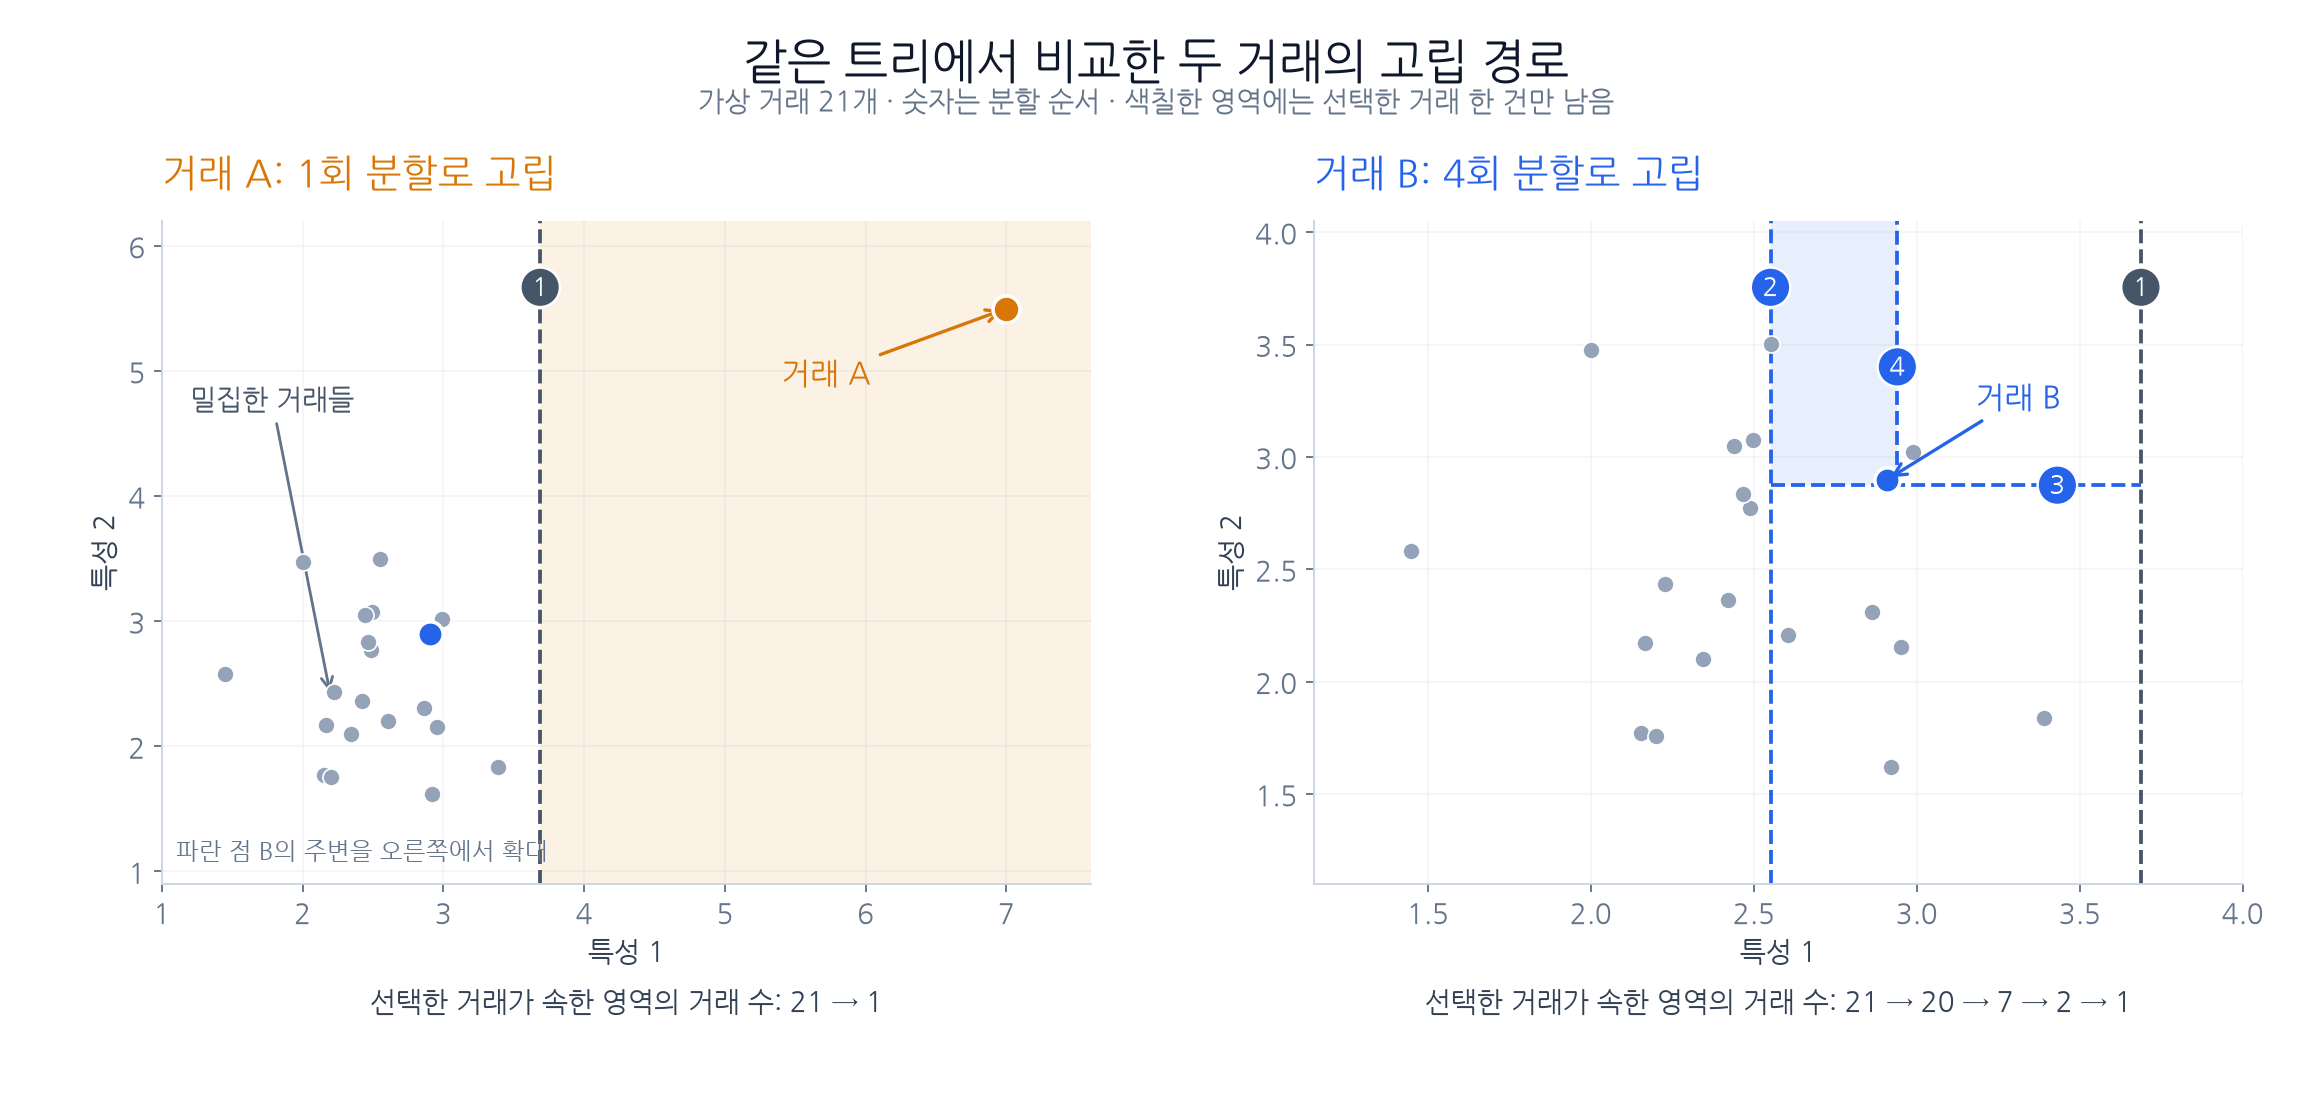

- 거래 A는 다른 거래에서 멀리 떨어져 있어 첫 번째 분할의 오른쪽 영역에 혼자 남는다. 고립까지 필요한 분할은 1회다.
- 거래 B는 첫 번째 분할 뒤에도 다른 거래와 함께 남는다. B가 속한 영역의 거래 수가 21 → 20 → 7 → 2 → 1로 줄어들며, 고립까지 4회의 분할이 필요하다.

이 트리에서 거래 A의 경로는 B보다 짧다. Isolation Forest는 여러 트리의 경로 길이를 종합해, 짧은 경로로 고립되는 거래에 높은 이상 점수를 부여한다.
여러 트리를 사용하면 한 번의 무작위 분할에 따른 영향을 줄일 수 있다.

이상 점수는 정상 학습 거래와 비교한 고립 정도를 나타낸다.
드문 정상 거래도 높은 점수를 받을 수 있고, 정상 패턴과 비슷한 사기는 낮은 점수를 받을 수 있다.
사기 탐지의 유용성은 실제 라벨과 비교해 평가한다.

### 모델 학습과 점수 계산

`IsolationForest`에 정상 학습 거래의 입력을 전달해 모델을 학습한다.
검증 거래에는 학습된 모델을 적용해 거래마다 이상 점수를 계산한다.


In [16]:
model = IsolationForest(
    n_estimators=100,  # 트리 수
    max_samples=256,  # 트리마다 뽑는 학습 거래 수
    random_state=SEED,
    n_jobs=-1,  # 학습에 사용 가능한 CPU 코어를 활용한다.
)
# fit: (정상 거래 수, 29) 입력으로 모델을 학습한다.
model.fit(normal_train_features)

# score_samples: 낮을수록 이상인 점수를 (거래 수,) 배열로 반환한다.
# 부호를 바꿔 클수록 이상인 점수로 사용한다.
val_scores = -model.score_samples(validation_features)

score_preview = validation[["record_id", "Amount", "Class"]].copy()
score_preview["anomaly_score"] = val_scores

# 이상 점수가 높은 거래부터 확인한다.
display(
    score_preview
    .sort_values("anomaly_score", ascending=False)
    .head(10)
)


,record_id,Amount,Class,anomaly_score
151006,151006,1.00,1,0.745889
154684,154684,0.01,1,0.742983
153823,153823,2.28,1,0.735052
220212,220212,303.80,0,0.734985
262843,262843,1441.06,0,0.724964
56335,56335,5934.90,0,0.720490
121787,121787,1729.79,0,0.719166
151519,151519,1.63,1,0.718336
168402,168402,970.00,0,0.718215
102441,102441,1.00,1,0.716524


## 탐지 성능 비교

사기를 양성(1)으로 두고, 이상 점수가 임계값 이상인 거래를 이상거래로 예측한다.
검증 결과에서 사기 탐지 성능과 이상거래 예측 건수(`predicted_count`)를 함께 비교한다.

| 지표 | 비교하는 내용 |
| --- | --- |
| F1 | 선택한 임계값에서 정밀도와 재현율의 조화평균 |
| AP(Average Precision) | 여러 임계값에서의 정밀도를 재현율 증가량으로 가중 평균한 값 |
| ROC-AUC | 사기 거래에 정상 거래보다 높은 점수를 주는 정도 |

### AP: 평균 정밀도

AP(Average Precision, 평균 정밀도)는 여러 임계값에서 얻은 정밀도를 재현율 증가량으로 가중 평균한 값이다.
AP는 0~1 범위이며, 높은 값은 사기를 많이 찾아내면서도 높은 정밀도를 유지함을 의미한다.

In [17]:
def detection_metrics(actual, scores, threshold):
    # actual과 scores: 같은 거래 순서의 (거래 수,) 라벨과 연속 점수.
    # asarray로 점수를 배열로 바꾸고, 임계값 이상인 거래를 True로 표시한다.
    predicted = np.asarray(scores) >= threshold

    # labels=[0, 1]인 2×2 혼동 행렬을 펼치면 TN, FP, FN, TP 순서다.
    tn, fp, fn, tp = confusion_matrix(
        actual,
        predicted,
        labels=[0, 1],
    ).ravel()

    # zero_division=0: 분모가 0인 정밀도·재현율·F1을 0으로 처리한다.
    return {
        "AP": average_precision_score(actual, scores),
        "ROC_AUC": roc_auc_score(actual, scores),
        "precision": precision_score(actual, predicted, zero_division=0),
        "recall": recall_score(actual, predicted, zero_division=0),
        "f1": f1_score(actual, predicted, zero_division=0),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "predicted_count": int(predicted.sum()),  # True인 거래 수를 합산한다.
    }


### 임계값별 탐지와 검토량 비교

검증 점수의 범위를 참고해 0.45부터 0.70까지 0.05 간격의 후보를 비교한다.
각 행에서 찾아낸 사기 수와 놓친 사기 수, 검토해야 할 이상거래 예측 건수를 함께 읽는다.
이 후보들은 점수의 일부 구간을 비교하기 위한 값이며, 다른 모델이나 데이터에서는 다시 정해야 한다.


In [18]:
THRESHOLDS = [0.45, 0.50, 0.55, 0.60, 0.65, 0.70]
rows = []

for threshold in THRESHOLDS:
    # **는 지표 딕셔너리의 항목을 현재 행에 합친다.
    rows.append({
        "threshold": threshold,
        **detection_metrics(y_val, val_scores, threshold),
    })

threshold_results = pd.DataFrame(rows)
display(threshold_results)


,threshold,AP,ROC_AUC,precision,recall,f1,TP,FP,FN,predicted_count
0,0.45,0.188026,0.946105,0.014041,0.894737,0.027648,68,4775,8,4843
1,0.50,0.188026,0.946105,0.040606,0.881579,0.077636,67,1583,9,1650
2,0.55,0.188026,0.946105,0.084584,0.815789,0.153276,62,671,14,733
3,0.60,0.188026,0.946105,0.126354,0.460526,0.198300,35,242,41,277
4,0.65,0.188026,0.946105,0.186047,0.210526,0.197531,16,70,60,86
5,0.70,0.188026,0.946105,0.333333,0.078947,0.127660,6,12,70,18


### 임계값별 결과 해석

이 결과에서는 임계값을 높일수록 이상거래 예측 건수와 오탐이 줄고 정밀도가 높아진다.
동시에 찾아내는 사기가 줄어 재현율은 낮아지고 미탐은 늘어난다.

F1은 처음에는 높아지다가, 임계값이 높아져 재현율이 크게 낮아지면 다시 감소한다.
임계값을 선택할 때는 사기를 찾아내는 정도와 검토해야 할 거래 수를 함께 고려한다.


### Isolation Forest 후보 비교


같은 정상 학습 거래로 트리 50개와 100개인 후보 모델을 학습한다.
각 모델에 같은 임계값 후보를 적용해 검증 결과를 비교한다.

검증 F1이 가장 높은 조합을 선택한다. 동점이면 FP가 적고, 트리 수가 적고, 임계값이 높은 순으로 고른다.
선택한 결과에서 사기 탐지 수와 검토량을 함께 확인한다.

In [19]:
TREE_COUNTS = [50, 100]
candidates, rows = {}, []

for trees in TREE_COUNTS:
    candidate = IsolationForest(
        n_estimators=trees,
        max_samples=256,
        random_state=SEED,
        n_jobs=-1,
    )
    candidate.fit(normal_train_features)
    # 선택한 모델을 다시 꺼낼 수 있도록 트리 수를 키로 저장한다.
    candidates[trees] = candidate
    scores = -candidate.score_samples(validation_features)

    for threshold in THRESHOLDS:
        rows.append({
            "trees": trees,
            "threshold": threshold,
            **detection_metrics(y_val, scores, threshold),
        })

# 앞 열부터 우선 정렬한다. False는 큰 값부터, True는 작은 값부터 정렬한다.
comparison = pd.DataFrame(rows).sort_values(
    ["f1", "FP", "trees", "threshold"],
    ascending=[False, True, True, False],
)
display(comparison)

# iloc[0]: 정렬된 표의 첫 행을 Series로 가져온다.
choice = comparison.iloc[0]
selected_model = candidates[int(choice["trees"])]
selected_threshold = float(choice["threshold"])
selected_scores = -selected_model.score_samples(validation_features)
print(
    "선택한 트리 수:", int(choice["trees"]),
    "/ 임계값:", selected_threshold,
)

# 오토인코더와 비교할 Isolation Forest의 모델·임계값·검증 점수를 보관한다.
forest_model = selected_model
forest_threshold = selected_threshold
forest_val_scores = selected_scores.copy()
forest_comparison = comparison.copy()


,trees,threshold,AP,ROC_AUC,precision,recall,f1,TP,FP,FN,predicted_count
9,100,0.60,0.188026,0.946105,0.126354,0.460526,0.198300,35,242,41,277
10,100,0.65,0.188026,0.946105,0.186047,0.210526,0.197531,16,70,60,86
8,100,0.55,0.188026,0.946105,0.084584,0.815789,0.153276,62,671,14,733
4,50,0.65,0.103043,0.944578,0.131313,0.171053,0.148571,13,86,63,99
2,50,0.55,0.103043,0.944578,0.071336,0.723684,0.129870,55,716,21,771
3,50,0.60,0.103043,0.944578,0.078788,0.342105,0.128079,26,304,50,330
11,100,0.70,0.188026,0.946105,0.333333,0.078947,0.127660,6,12,70,18
5,50,0.70,0.103043,0.944578,0.285714,0.078947,0.123711,6,15,70,21
7,100,0.50,0.188026,0.946105,0.040606,0.881579,0.077636,67,1583,9,1650
1,50,0.50,0.103043,0.944578,0.039309,0.868421,0.075214,66,1613,10,1679


선택한 트리 수: 100 / 임계값: 0.6


### 이상 점수 분포 읽기

가로축은 이상 점수, 세로축은 해당 점수 구간의 거래 수다. 파란색은 정상, 주황색은 사기 거래이며, 검은 점선은 선택한 임계값이다.
세로축은 로그 눈금으로 정상 거래와 사기 거래의 큰 빈도 차이를 함께 보여준다.

정상·사기 점수가 겹치는 구간을 확인한다.
임계값 오른쪽의 정상 거래는 오탐이고, 왼쪽의 사기 거래는 미탐이다.


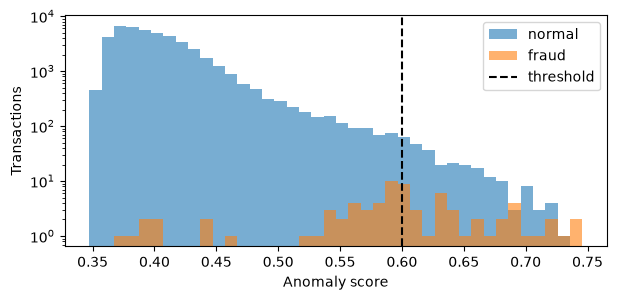

In [20]:
fig, ax = plt.subplots(figsize=(7, 3))
# 두 집단을 같은 40개 점수 구간으로 나누어 빈도를 비교한다.
bins = np.histogram_bin_edges(selected_scores, bins=40)

for label, title in [(0, "normal"), (1, "fraud")]:
    ax.hist(
        selected_scores[y_val == label],
        bins=bins,
        alpha=0.6,  # 겹치는 막대를 볼 수 있도록 투명도를 지정한다.
        label=title,
    )

# axvline: 선택한 임계값 위치에 세로선을 그린다.
ax.axvline(
    selected_threshold,
    color="black",
    linestyle="--",
    label="threshold",
)
ax.set(xlabel="Anomaly score", ylabel="Transactions", yscale="log")
ax.legend()
plt.show()


## 오토인코더로 정상 거래 학습하기

정상 거래로 오토인코더를 학습하고, 거래별 복원 오차(MSE)를 이상 점수로 사용한다.
정상 패턴에서 벗어난 거래는 복원 오차가 커질 수 있다.
드문 정상 거래도 오차가 클 수 있고, 정상과 비슷한 사기는 오차가 작을 수 있다.

특성별 척도를 맞추기 위해 정상 학습 거래를 기준으로 표준화한다.
검증·테스트와 새 거래에도 같은 기준을 적용한다.


In [21]:
ae_scaler = StandardScaler()
# fit_transform: 정상 학습 거래로 통계를 구하고 변환한다.
X_ae_train = ae_scaler.fit_transform(normal_train_features).astype("float32")
X_ae_val = ae_scaler.transform(validation_features).astype("float32")
X_ae_test = ae_scaler.transform(test_features).astype("float32")

# 학습 중 복원 품질은 검증 집합의 정상 거래로 확인한다.
X_ae_val_normal = X_ae_val[y_val == 0]
print("정상 학습 입력:", X_ae_train.shape)
print("정상 검증 입력:", X_ae_val_normal.shape)
display(pd.DataFrame(
    X_ae_train[:5],
    columns=train_features.columns,
))


정상 학습 입력: (181282, 29)
정상 검증 입력: (45320, 29)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,log_amount
0,-2.432499,2.395924,-0.247406,-1.560784,-0.784705,-0.650506,0.094898,0.495823,2.598255,3.874733,...,2.479646,-0.651039,-0.443175,0.306699,0.096298,0.673818,1.527163,2.543883,1.562335,-1.004682
1,-0.625945,-0.033021,0.123353,-0.562187,-2.040515,1.575126,1.938225,0.244518,0.168311,-1.328345,...,-0.093411,-0.109908,-0.108358,0.672112,-1.224499,-1.362915,1.430443,0.281351,-0.147135,1.972228
2,-1.117762,-0.282298,0.693891,0.400857,-0.574775,-0.060759,-0.227031,0.202121,-0.897190,0.695469,...,-1.227289,-0.490439,0.360909,0.360075,-0.121211,0.185860,-0.278660,0.723408,-0.113829,0.987018
3,0.760113,-0.460792,-1.344009,1.181064,-0.005903,-0.879545,0.834432,-0.397777,0.309682,0.151551,...,0.295503,0.288255,0.145875,-0.397937,0.061014,0.625160,-1.086121,-0.209565,-0.040883,1.540127
4,0.448956,0.024776,0.642831,1.735806,-0.266286,0.395004,-0.227588,0.212192,-0.698342,0.711288,...,0.083288,0.357237,0.683069,-0.187939,0.037831,0.528159,0.142495,0.013064,0.105903,0.937185


### 신경망 구성

구조는 `29 → 16 → 잠재 차원 → 16 → 29`이며, 잠재 차원은 4와 8을 비교한다.
마지막 층은 표준화 입력의 음수·양수를 모두 복원할 수 있도록 선형 출력을 사용한다.


In [24]:
# CPU에서 실행하며, 작은 신경망의 연산에 사용할 스레드 수를 정한다.
torch.set_num_threads(2)


class TransactionAutoencoder(nn.Module):
    def __init__(self, input_dim=29, latent_dim=8):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 16),  # 입력 특성 수 → 출력 특성 수
            nn.ReLU(),
            nn.Linear(16, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 16),
            nn.ReLU(),
            nn.Linear(16, input_dim),
        )

    def forward(self, inputs):
        # 입력과 복원값의 모양은 모두 (배치 거래 수, 29)다.
        return self.decoder(self.encoder(inputs))


### 학습과 가중치 선택

모델 학습에는 정상 거래만 사용한다.
정상 거래의 복원 오차를 줄이도록 가중치를 갱신하여 정상 패턴을 학습한다.

정상 검증 거래의 MSE가 가장 작은 에포크의 가중치를 선택한다.
사기 거래는 정상 거래와 함께 검증 집합에서 탐지 성능을 평가하고 임계값을 선택하는 데 사용한다.


In [25]:
def fit_autoencoder(latent_dim, epochs):
    # manual_seed: 가중치 초기화와 학습 순서의 난수 시드를 고정한다.
    torch.manual_seed(SEED)
    model = TransactionAutoencoder(X_ae_train.shape[1], latent_dim)

    # from_numpy: 배열을 텐서로 변환. TensorDataset: 거래별로 꺼낼 데이터셋.
    dataset = TensorDataset(torch.from_numpy(X_ae_train))
    loader = DataLoader(
        dataset,
        batch_size=512,  # 한 번에 학습할 거래 수
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    validation_tensor = torch.from_numpy(X_ae_val_normal)
    # parameters(): 학습할 가중치, lr: 가중치 갱신 크기를 조절하는 학습률.
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_function = nn.MSELoss()  # 배치의 거래·특성 전체에 대한 평균 제곱 오차
    best_loss = float("inf")
    best_state = None
    rows = []

    for epoch in range(epochs):
        model.train()  # 학습 모드
        total_loss = 0.0

        for (inputs,) in loader:
            optimizer.zero_grad()  # 이전 배치의 기울기를 비운다.
            restored = model(inputs)
            loss = loss_function(restored, inputs)
            loss.backward()  # 가중치별 손실의 기울기를 계산한다.
            optimizer.step()  # 계산한 기울기로 가중치를 갱신한다.
            # item(): 손실 텐서를 숫자로 꺼낸다. 거래 수로 가중해 합산한다.
            total_loss += loss.item() * len(inputs)

        model.eval()  # 평가 모드
        with torch.no_grad():  # 평가에는 기울기를 기록하지 않는다.
            validation_loss = loss_function(
                model(validation_tensor),
                validation_tensor,
            ).item()

        if validation_loss < best_loss:
            best_loss = validation_loss
            # state_dict: 가중치 묶음. 이후 학습과 분리해 복사한다.
            best_state = deepcopy(model.state_dict())

        rows.append({
            "epoch": epoch + 1,
            "train_MSE": total_loss / len(X_ae_train),
            "normal_val_MSE": validation_loss,
        })

    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(rows)


### 잠재 차원별 학습 결과

잠재 차원 4와 8인 모델을 각각 20에포크 학습한다.
그래프의 가로축은 에포크, 세로축은 정상 거래의 평균 복원 MSE다.
학습 손실이 줄어들 때 정상 검증 손실도 함께 줄어드는지 확인한다.


AE_4 학습 완료
AE_8 학습 완료


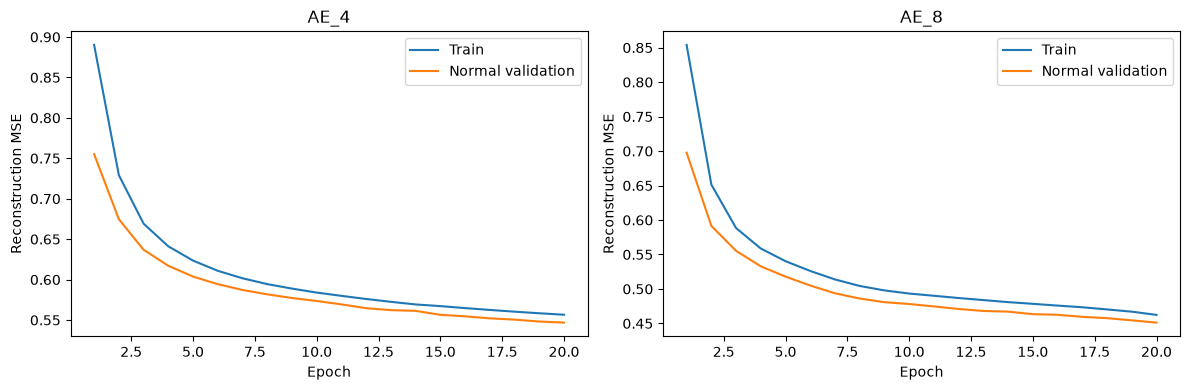

In [26]:
AE_LATENT_DIMS = [4, 8]
AE_EPOCHS = 20

ae_models = {}
ae_histories = {}
for latent_dim in AE_LATENT_DIMS:
    name = f"AE_{latent_dim}"
    ae_models[name], ae_histories[name] = fit_autoencoder(
        latent_dim=latent_dim,
        epochs=AE_EPOCHS,
    )
    print(name, "학습 완료")

# squeeze=False: 모델 수가 바뀌어도 axes를 2차원 배열로 유지한다.
fig, axes = plt.subplots(1, len(ae_models), figsize=(12, 4), squeeze=False)
for ax, (name, history) in zip(axes[0], ae_histories.items()):
    ax.plot(history["epoch"], history["train_MSE"], label="Train")
    ax.plot(history["epoch"], history["normal_val_MSE"], label="Normal validation")
    ax.set(title=name, xlabel="Epoch", ylabel="Reconstruction MSE")
    ax.legend()
plt.tight_layout()
plt.show()


### 거래별 이상 점수 계산

학습 손실은 여러 거래의 복원 오차를 평균한 값이다.
이상 탐지에는 각 거래의 29개 특성에 대한 평균 제곱 오차를 사용한다.
검증 입력을 복원하고 거래별 이상 점수를 구한다.


In [27]:
@torch.no_grad()  # 함수 전체에서 기울기 기록을 끈다.
def reconstruction_scores(model, values):
    model.eval()
    restored = model(torch.from_numpy(values)).numpy()
    # axis=1: 각 행의 29개 특성 오차를 평균해 (거래 수,) 점수를 만든다.
    scores = ((values - restored) ** 2).mean(axis=1)
    return restored, scores  # (거래 수, 29) 복원값, (거래 수,) 점수


ae_val_scores = {}
for name, ae_model in ae_models.items():
    _, ae_val_scores[name] = reconstruction_scores(ae_model, X_ae_val)


### 복원 점수의 임계값 비교

이 실습에서는 정상 검증 거래의 복원 점수에서 95%·99%·99.5% 분위수를 구해 후보 임계값으로 비교한다.
99% 분위수는 정상 검증 점수 약 99%가 그 이하에 놓이는 값이다.

정상·사기를 포함한 같은 검증 거래에서 후보별 F1·정밀도·재현율·이상거래 예측 건수를 비교한다.
검증에서 계산한 임계값은 고정해서 테스트에 적용한다. 이후 거래에서 이상거래로 예측하는 비율은 점수 분포와 동점 수에 따라 달라질 수 있다.


In [28]:
AE_QUANTILES = [0.95, 0.99, 0.995]
ae_rows = []

for name, scores in ae_val_scores.items():
    for quantile in AE_QUANTILES:
        threshold = float(np.quantile(scores[y_val == 0], quantile))
        ae_rows.append({
            "model": name,
            "quantile": quantile,
            "threshold": threshold,
            **detection_metrics(y_val, scores, threshold),
        })

ae_comparison = pd.DataFrame(ae_rows).sort_values(
    ["f1", "FP", "model", "quantile"],
    ascending=[False, True, True, False],
)
display(ae_comparison)


,model,quantile,threshold,AP,ROC_AUC,precision,recall,f1,TP,FP,FN,predicted_count
2,AE_4,0.995,3.801000,0.453315,0.951984,0.217241,0.828947,0.344262,63,227,13,290
5,AE_8,0.995,3.691698,0.417547,0.939998,0.217241,0.828947,0.344262,63,227,13,290
1,AE_4,0.990,2.478523,0.453315,0.951984,0.123552,0.842105,0.215488,64,454,12,518
4,AE_8,0.990,2.301928,0.417547,0.939998,0.123552,0.842105,0.215488,64,454,12,518
0,AE_4,0.950,1.193192,0.453315,0.951984,0.028302,0.868421,0.054817,66,2266,10,2332
3,AE_8,0.950,1.018678,0.417547,0.939998,0.028302,0.868421,0.054817,66,2266,10,2332


### 복원 점수 분포와 탐지 결과

검증 F1이 가장 높은 오토인코더와 임계값을 선택해 정상·사기 거래의 점수 분포를 그린다.
임계값 오른쪽의 정상 거래는 오탐, 사기 거래는 탐지한 사기에 해당한다.

큰 복원 오차까지 함께 표시하도록 가로축에는 `log1p(복원 MSE)`를 사용한다.
임계값에도 같은 변환을 적용하며, 이상거래 여부는 원래 점수로 판단한다.
세로축은 거래 수의 로그 척도다.


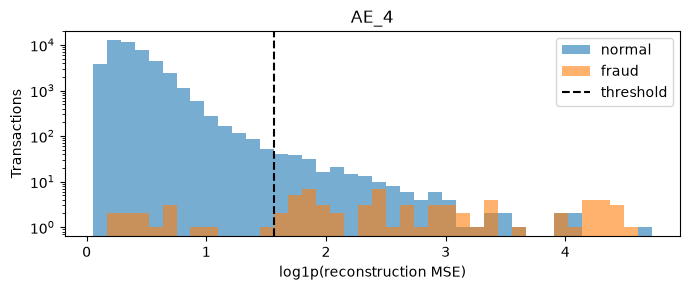

사기 76건 중 63건 탐지, 13건 미탐
정상 45320건 중 227건 오탐


In [29]:
ae_choice = ae_comparison.iloc[0]
selected_ae_name = str(ae_choice["model"])
selected_ae = ae_models[selected_ae_name]
ae_threshold = float(ae_choice["threshold"])
ae_scores = ae_val_scores[selected_ae_name]

# 시각화에만 로그 변환을 적용하고 두 집단에 같은 구간을 사용한다.
plotted_ae_scores = np.log1p(ae_scores)
bins = np.histogram_bin_edges(plotted_ae_scores, bins=40)
fig, ax = plt.subplots(figsize=(7, 3))

for label, caption in [(0, "normal"), (1, "fraud")]:
    ax.hist(
        plotted_ae_scores[y_val == label],
        bins=bins,
        alpha=0.6,
        label=caption,
    )

ax.axvline(
    np.log1p(ae_threshold),
    color="black",
    linestyle="--",
    label="threshold",
)
ax.set(
    title=selected_ae_name,
    xlabel="log1p(reconstruction MSE)",
    ylabel="Transactions",
    yscale="log",
)
ax.legend()
plt.tight_layout()
plt.show()

# 탐지와 오탐 건수는 변환 전 점수와 선택한 임계값으로 계산한다.
ae_metrics = detection_metrics(y_val, ae_scores, ae_threshold)
print(f"사기 {y_val.sum()}건 중 {ae_metrics['TP']}건 탐지, {ae_metrics['FN']}건 미탐")
print(f"정상 {(y_val == 0).sum()}건 중 {ae_metrics['FP']}건 오탐")


## 두 모델의 탐지 결과 비교

### 검증 결과로 모델 선택하기

Isolation Forest와 각 오토인코더에서 검증 F1이 가장 높은 임계값을 한 표로 비교한다.
같은 거래에서 AP·정밀도·재현율·F1과 오탐·미탐·이상거래 예측 건수를 읽는다.
모델별 이상거래 예측 건수가 다르므로 찾아낸 사기 수와 필요한 검토량을 함께 비교한다.

검증 F1이 가장 높은 모델을 선택한다. 동점이면 FP가 적고 모델 이름이 앞선 후보를 고른다.
선택은 현재 비교한 설정과 임계값 후보에 대한 결과다.


In [30]:
model_rows = [{
    "model": "IsolationForest",
    "threshold": forest_threshold,
    **detection_metrics(y_val, forest_val_scores, forest_threshold),
}]
for name in ae_models:
    best = ae_comparison.loc[ae_comparison["model"] == name].iloc[0]
    model_rows.append({
        "model": name,
        "threshold": float(best["threshold"]),
        **detection_metrics(y_val, ae_val_scores[name], float(best["threshold"])),
    })

comparison = pd.DataFrame(model_rows).sort_values(
    ["f1", "FP", "model"],
    ascending=[False, True, True],
)
display(comparison)

choice = comparison.iloc[0]
selected_name = str(choice["model"])
selected_threshold = float(choice["threshold"])
models = {"IsolationForest": forest_model, **ae_models}
validation_scores = {"IsolationForest": forest_val_scores, **ae_val_scores}
selected_model = models[selected_name]
selected_scores = validation_scores[selected_name]
print("선택한 모델:", selected_name, "/ 임계값:", selected_threshold)


,model,threshold,AP,ROC_AUC,precision,recall,f1,TP,FP,FN,predicted_count
1,AE_4,3.801000,0.453315,0.951984,0.217241,0.828947,0.344262,63,227,13,290
2,AE_8,3.691698,0.417547,0.939998,0.217241,0.828947,0.344262,63,227,13,290
0,IsolationForest,0.600000,0.188026,0.946105,0.126354,0.460526,0.198300,35,242,41,277


선택한 모델: AE_4 / 임계값: 3.800999879837036


### 모델별 점수 분포 읽기

각 그래프에서 정상·사기 점수의 겹치는 구간과 모델별 임계값을 확인한다.
오토인코더의 점수 분포를 그릴 때 사용한 `log1p` 변환을 모든 모델의 이상 점수에 동일하게 적용한다.
이 변환은 큰 점수 사이의 간격을 줄여 분포를 보기 쉽게 하며, 임계값에도 동일하게 적용한다.
이상거래 판단과 성능 평가는 변환 전 점수를 사용한다.


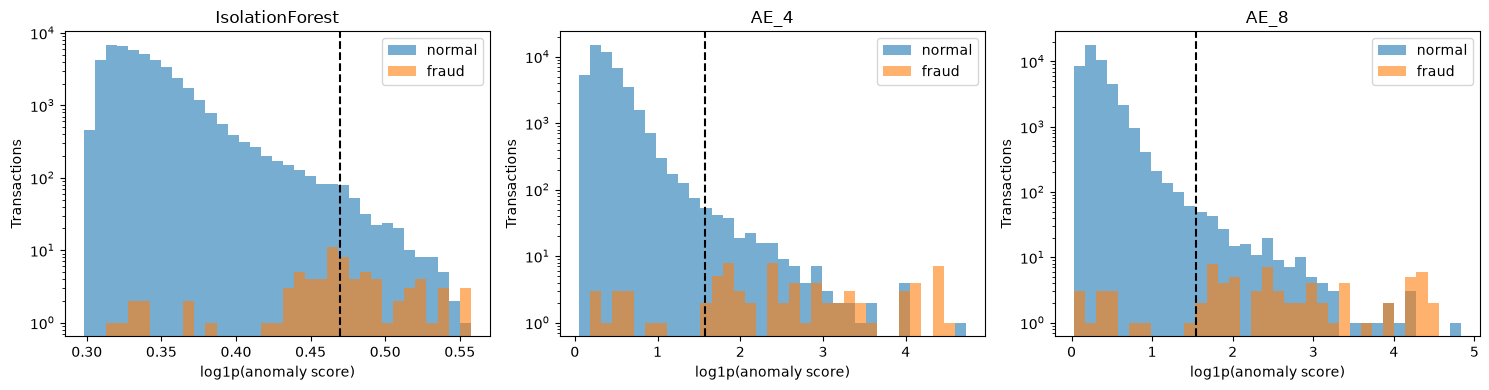

In [31]:
fig, axes = plt.subplots(1, len(models), figsize=(15, 4), squeeze=False)
for ax, name in zip(axes[0], models):
    plotted_scores = np.log1p(validation_scores[name])
    bins = np.histogram_bin_edges(plotted_scores, bins=35)

    for label, caption in [(0, "normal"), (1, "fraud")]:
        ax.hist(
            plotted_scores[y_val == label],
            bins=bins,
            alpha=0.6,
            label=caption,
        )

    threshold = float(
        comparison.loc[comparison["model"] == name, "threshold"].iloc[0]
    )
    ax.axvline(np.log1p(threshold), color="black", linestyle="--")
    ax.set(
        title=name,
        xlabel="log1p(anomaly score)",
        ylabel="Transactions",
        yscale="log",
    )
    ax.legend()
plt.tight_layout()
plt.show()


### 최종 테스트

검증 단계에서 선택한 모델과 임계값을 고정해 테스트 거래를 평가한다.
검증과 테스트의 사기 수·AP·ROC-AUC·정밀도·재현율·FP·FN을 비교한다.
사기 거래 수가 적어 일부 거래의 구성이나 순위 차이도 평가 지표에 영향을 줄 수 있다.


In [32]:
# 선택된 모델에 맞는 입력 변환과 점수 계산을 적용한다.
if selected_name == "IsolationForest":
    test_scores = -selected_model.score_samples(test_features)
else:
    _, test_scores = reconstruction_scores(selected_model, X_ae_test)

test_metrics = detection_metrics(y_test, test_scores, selected_threshold)
display(pd.DataFrame([
    {
        "model": selected_name,
        "split": "validation",
        "fraud": int(y_val.sum()),
        **detection_metrics(y_val, selected_scores, selected_threshold),
    },
    {
        "model": selected_name,
        "split": "test",
        "fraud": int(y_test.sum()),
        **test_metrics,
    },
]))
print(
    f"사기 {y_test.sum()}건 중 {test_metrics['TP']}건 탐지, "
    f"{test_metrics['FN']}건 미탐"
)
print(f"이상거래로 예측한 {test_metrics['predicted_count']}건 중 정상 거래 {test_metrics['FP']}건")
print(f"정밀도 {test_metrics['precision']:.1%}, 재현율 {test_metrics['recall']:.1%}")


,model,split,fraud,AP,ROC_AUC,precision,recall,f1,TP,FP,FN,predicted_count
0,AE_4,validation,76,0.453315,0.951984,0.217241,0.828947,0.344262,63,227,13,290
1,AE_4,test,95,0.319563,0.923969,0.192837,0.736842,0.305677,70,293,25,363


사기 95건 중 70건 탐지, 25건 미탐
이상거래로 예측한 363건 중 정상 거래 293건
정밀도 19.3%, 재현율 73.7%


### 혼동 행렬과 ROC·PR 곡선

선택한 모델의 테스트 결과를 혼동 행렬과 ROC·PR 곡선으로 확인한다.
PR 곡선의 점선은 테스트 거래의 사기 비율이다.


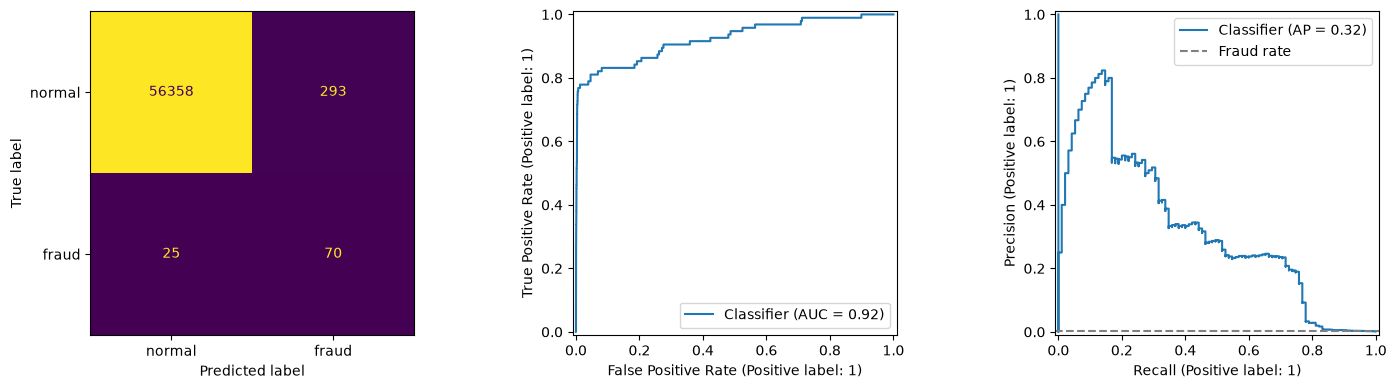

In [33]:
# subplots: Figure와 가로로 배치한 세 그래프의 Axes 배열을 반환한다.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 혼동 행렬에는 실제 라벨과 임계값으로 구분한 예측 라벨을 전달한다.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_scores >= selected_threshold,
    display_labels=["normal", "fraud"],
    ax=axes[0],
    colorbar=False,
)

# ROC·PR 곡선에는 실제 라벨과 연속 점수를 전달한다.
RocCurveDisplay.from_predictions(y_test, test_scores, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, test_scores, ax=axes[2])
axes[2].axhline(
    y_test.mean(),
    color="gray",
    linestyle="--",
    label="Fraud rate",
)
axes[2].legend()
plt.tight_layout()
plt.show()


### 탐지 결과 해석

사기를 찾아낸 건수와 놓친 건수, 이상거래로 잘못 예측한 정상 거래 수를 읽는다.
정밀도·재현율과 검토량을 함께 고려해 선택한 모델의 결과를 설명한다.

현재 결과를 실제 운영에 적용하려면 이후 기간의 거래에서도 성능을 확인하고, 이상거래 예측 건수를 처리 가능한 검토량과 비교해야 한다.


## 실습: 모델 개선하기

Isolation Forest의 트리 수와 오토인코더의 잠재 차원·학습 횟수를 조절해 모델을 개선해 보자.
같은 검증 데이터에서 변경 전후의 성능을 비교하고, 결과가 어떻게 달라졌는지 설명한다.
정상·사기 거래의 이상 점수 분포를 확인하고, 사기를 놓치는 경우와 정상 거래를 사기로 판단하는 경우를 고려해 적절한 임계값을 설정한다.
